In [3]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import harmonypy as hm
import scanorama
import umap
import matplotlib.pyplot as plt

In [4]:
#Read in microglia unprocessed
script_loc = Path('integration.ipynb').parent.resolve()
data_loc = script_loc.parent / "data/intermediate"
resources_loc = script_loc.parent / 'resources'

mdata = sc.read_h5ad(data_loc / "microglia_preprocessed.h5ad")

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\3275647200.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.highly_variable_genes(mdata, save='.png')


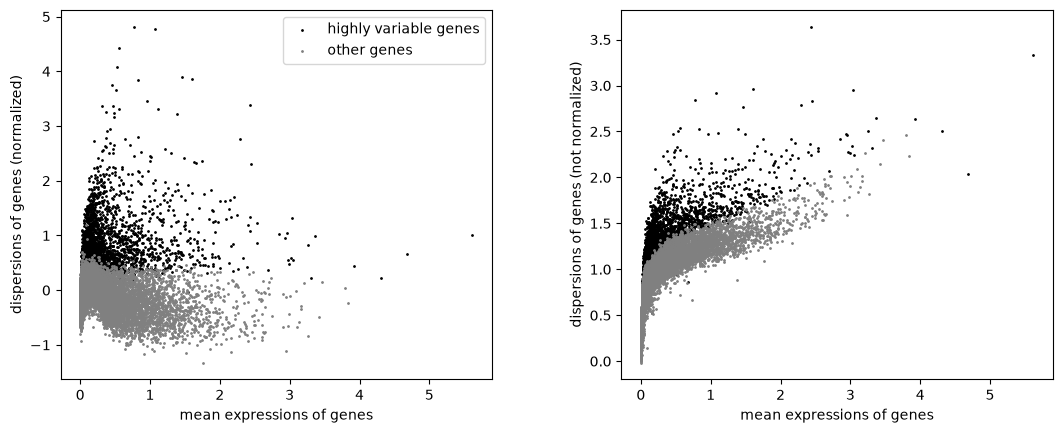

In [5]:
#Find the top 3500 variable genes
sc.settings.figdir = script_loc.parent / 'outputs/integration_figures'
sc.pp.highly_variable_genes(mdata, n_top_genes=3500, layer='CP10k_counts', batch_key='id')
sc.pl.highly_variable_genes(mdata, save='.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\1882503536.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca_variance_ratio(mdata, n_pcs=50, log=False, save='.png')


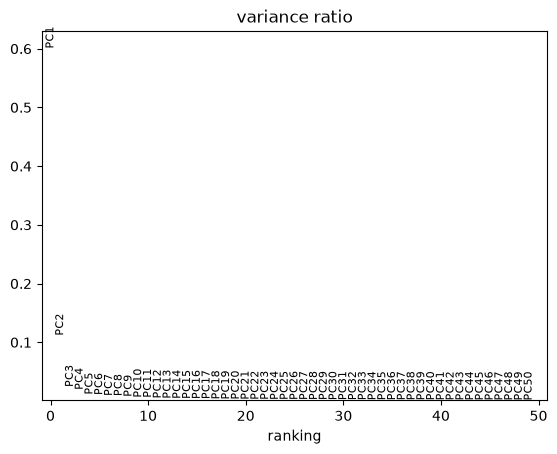

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\1882503536.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca_variance_ratio(mdata, n_pcs=50, log=True, save='_log.png')


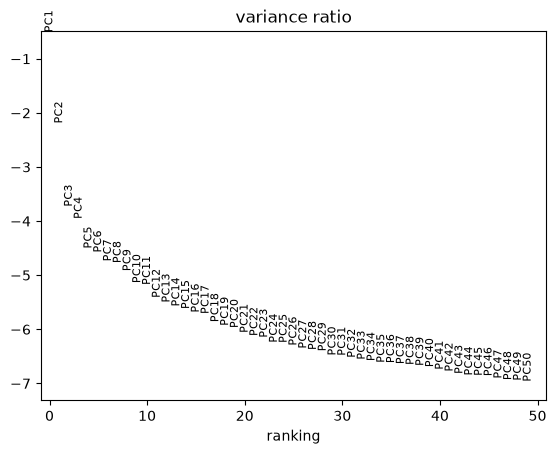

In [6]:
#Find PCs and plot variance ratio
sc.tl.pca(mdata)
sc.pl.pca_variance_ratio(mdata, n_pcs=50, log=False, save='.png')
sc.pl.pca_variance_ratio(mdata, n_pcs=50, log=True, save='_log.png')

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2128134911.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca(


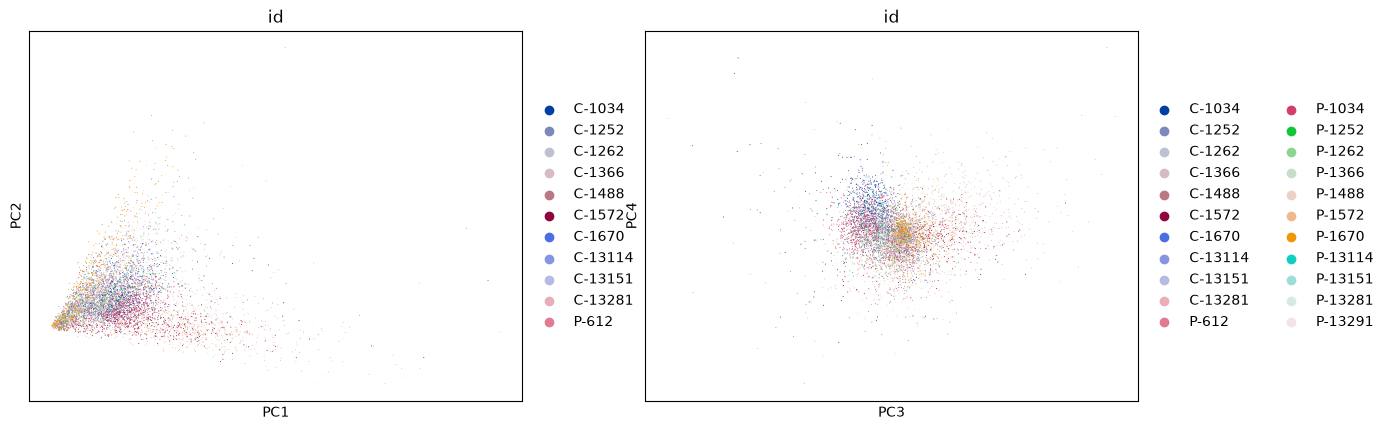

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2128134911.py:11: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca(


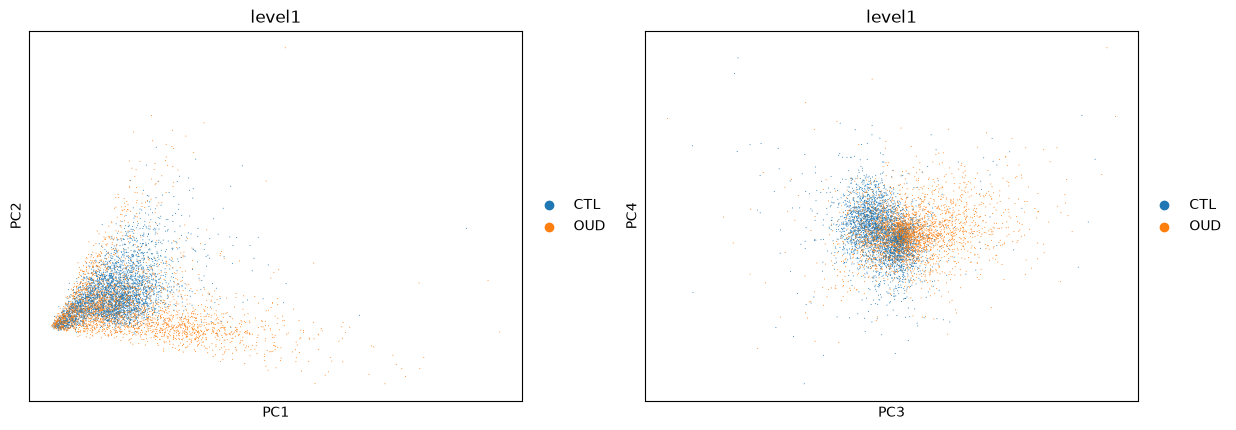

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2128134911.py:19: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.pca(


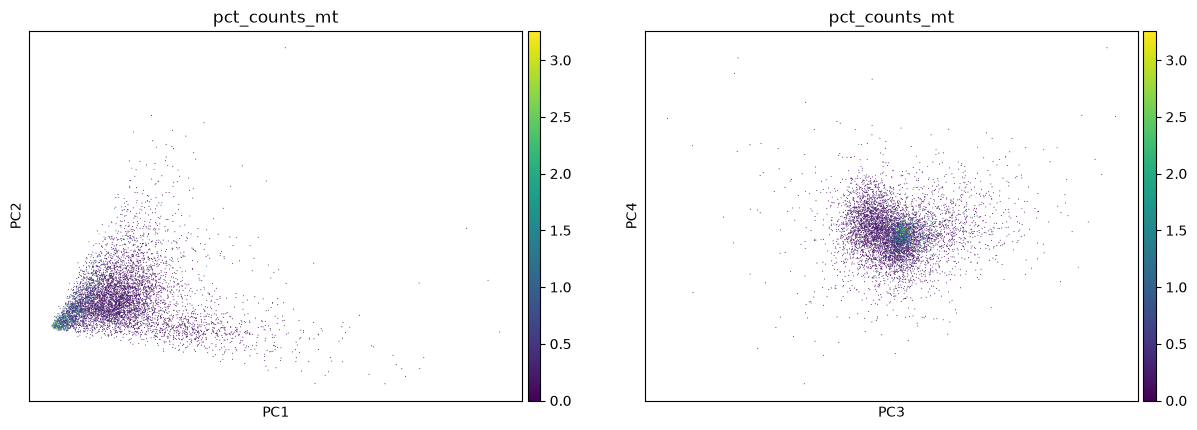

In [7]:
#Create and save PC1,2 and 3,4 of cells, coloring with batch, diagnosis, and pct_counts_mt 
#to investigate differences
sc.pl.pca(
    mdata,
    color=["id", "id",],
    dimensions=[(0, 1), (2, 3)],
    ncols=2,
    size=2,
    save='_batch.png'
)
sc.pl.pca(
    mdata,
    color=["level1", "level1"],
    dimensions=[(0, 1), (2, 3)],
    ncols=2,
    size=2,
    save='_dx.png'
)
sc.pl.pca(
    mdata,
    color=["pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3)],
    ncols=2,
    size=2,
    save='_qc.png'
)

In [8]:
#Copy the data to enable comparison of two batch integration methods
hmdata = mdata.copy()
smdata = mdata.copy()

In [9]:
#Calculate neighbors and umap coordinates
sc.pp.neighbors(mdata)
sc.tl.umap(mdata)

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2376221318.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


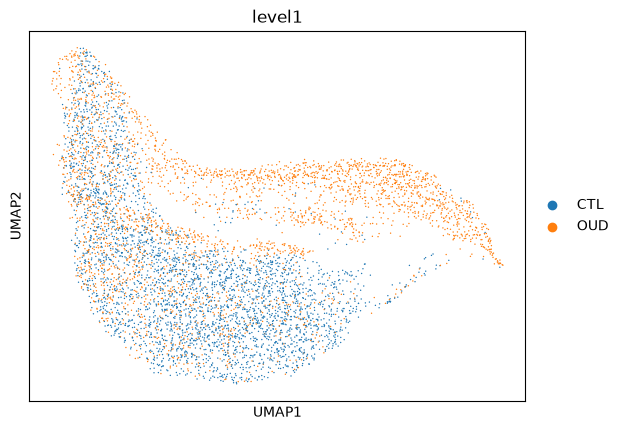

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2376221318.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


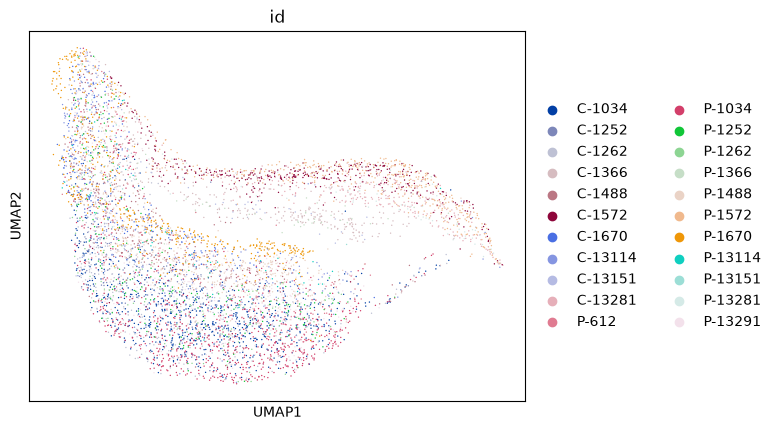

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2376221318.py:14: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


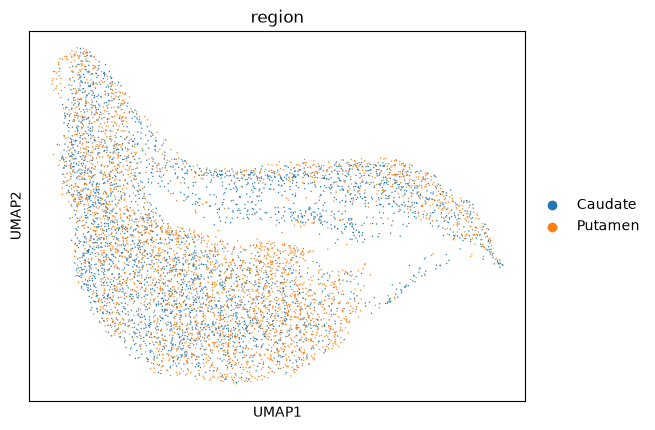

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\2376221318.py:20: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


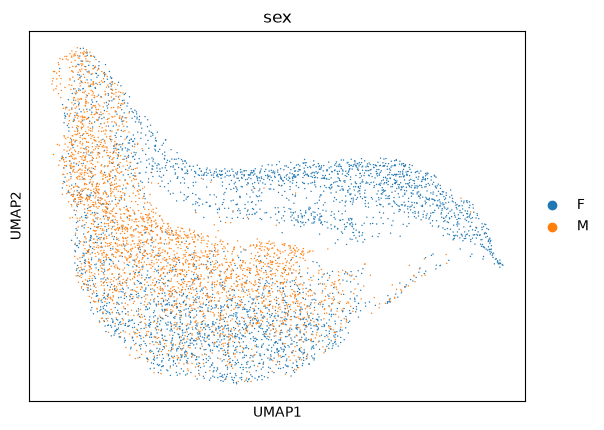

In [ ]:
#Create and save umap plots colored by diagnosis, sample, sex, and region
sc.pl.umap(
    mdata,
    color="level1",
    size=4,
    save='_dx_uncorrected.png'
)
sc.pl.umap(
    mdata,
    color="id",
    size=4,
    save='_sample_uncorrected.png'
)
sc.pl.umap(
    mdata,
    color="region",
    size=4,
    save='_region_uncorrected.png'
)
sc.pl.umap(
    mdata,
    color="sex",
    size=4,
    save='_sex_uncorrected.png'
)

In [11]:
#Integrate data using harmonypy
pcs = hmdata.obsm['X_pca']
harmony_out = hm.run_harmony(pcs, mdata.obs, "id")
hmdata.obsm['X_pca_harmony'] = harmony_out.Z_corr
hmdata

2026-10-25 18:19:18,793 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-25 18:19:18,794 - harmonypy - INFO -   Parameters:
2026-10-25 18:19:18,794 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-25 18:19:18,795 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-25 18:19:18,796 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-25 18:19:18,797 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-25 18:19:18,798 - harmonypy - INFO -     nclust: 100
2026-10-25 18:19:18,798 - harmonypy - INFO -     block_size: 0.05
2026-10-25 18:19:18,799 - harmonypy - INFO -     lamb: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
2026-10-25 18:19:18,800 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-25 18:19:18,801 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-25 18:19:18,802 - harmonypy - INFO -     verbose: True
2026-10-25 18:19:18,802 - harmonypy - INFO -     random_stat

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'id_col

In [12]:
#Calculate neighbors and umap on corrected pcs
sc.pp.neighbors(hmdata, use_rep='X_pca_harmony')
sc.tl.umap(hmdata)

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4213749489.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


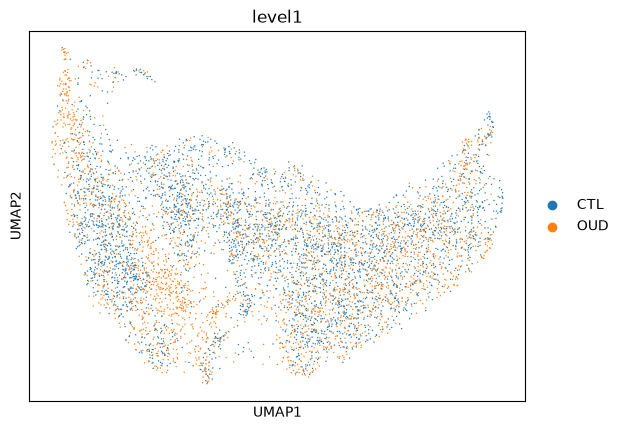

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4213749489.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


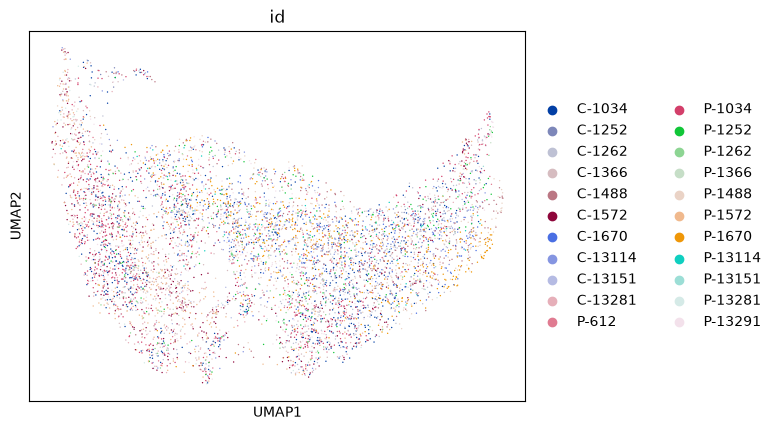

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4213749489.py:13: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


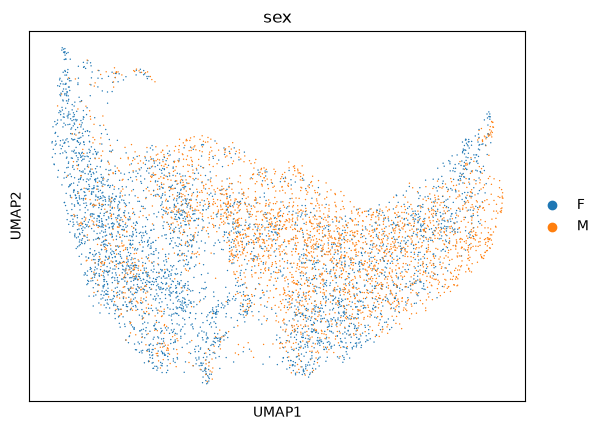

In [13]:
sc.pl.umap(
    hmdata,
    color="level1",
    size=4,
    save='_dx_hm.png'
)
sc.pl.umap(
    hmdata,
    color="id",
    size=4,
    save='_sample_hm.png'
)
sc.pl.umap(
    hmdata,
    color="sex",
    size=4,
    save='_sex_hm.png'
)

In [14]:
smdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'id_col

In [15]:
#Integrate data using scanorama
smdata.X = smdata.layers['CP10k_counts']
batch_key = 'id'
mdatas = [smdata[smdata.obs[batch_key] == batch_value].copy() for batch_value in smdata.obs[batch_key].unique()]
print(len(mdatas))

22


In [16]:
scanorama.integrate_scanpy(mdatas, dimred = 100)
scanorama_int = [ad.obsm['X_scanorama'] for ad in mdatas]

all_s = np.concatenate(scanorama_int)

smdata.obsm['X_scanorama'] = all_s
smdata

Found 24087 genes among all datasets
[[0.         0.19285714 0.27386935 0.25       0.         0.00961538
  0.01167315 0.12895928 0.         0.0201005  0.9389313  0.06018519
  0.12711864 0.         0.         0.0125     0.0170068  0.
  0.01679104 0.0025413  0.         0.0141844 ]
 [0.         0.         0.62142857 0.21428571 0.01724138 0.
  0.01428571 0.12142857 0.         0.02512563 0.06428571 0.90714286
  0.11864407 0.03703704 0.         0.         0.04285714 0.
  0.02142857 0.         0.00714286 0.05      ]
 [0.         0.         0.         0.31666667 0.06896552 0.01282051
  0.07392996 0.260181   0.01005025 0.04522613 0.10552764 0.50462963
  0.88135593 0.01851852 0.         0.0125     0.22864322 0.
  0.03266332 0.00502513 0.00251256 0.02836879]
 [0.         0.         0.         0.         0.18965517 0.02666667
  0.02       0.57666667 0.07       0.29648241 0.07333333 0.27314815
  0.15254237 0.90740741 0.         0.025      0.22       0.
  0.27333333 0.         0.16       0.30496454]

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'id_col

In [17]:
#Calculate neighbors and umap on corrected pcs
sc.pp.neighbors(smdata, use_rep='X_scanorama')
sc.tl.umap(smdata)

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4074720470.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


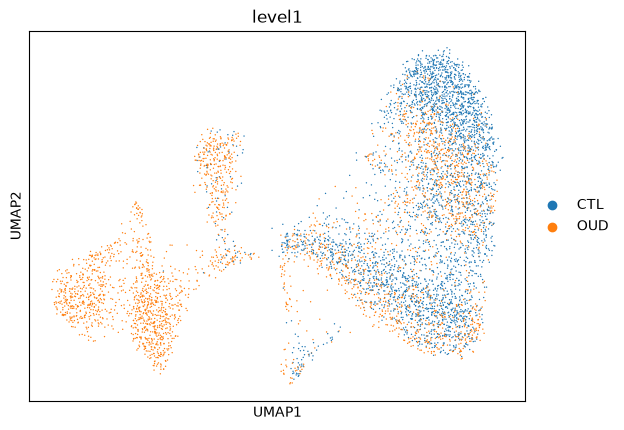

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4074720470.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


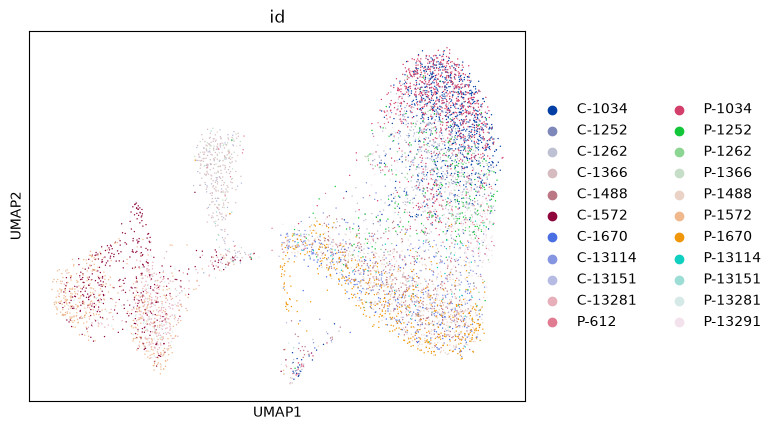

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\4074720470.py:14: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


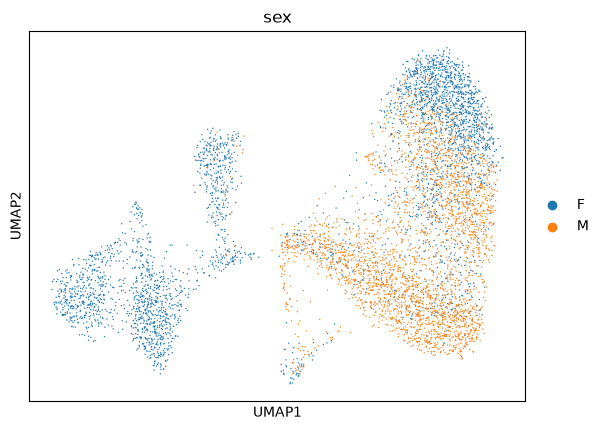

In [18]:
sc.pl.umap(
    smdata,
    color="level1",
    size=4,
    save='_dx_sr.png'
)
sc.pl.umap(
    smdata,
    color="id",
    size=4,
    save='_sample_sr.png'
)

sc.pl.umap(
    smdata,
    color="sex",
    size=4,
    save='_sex_sr.png'
)

C:\Users\chris\AppData\Local\Temp\ipykernel_25812\437255362.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


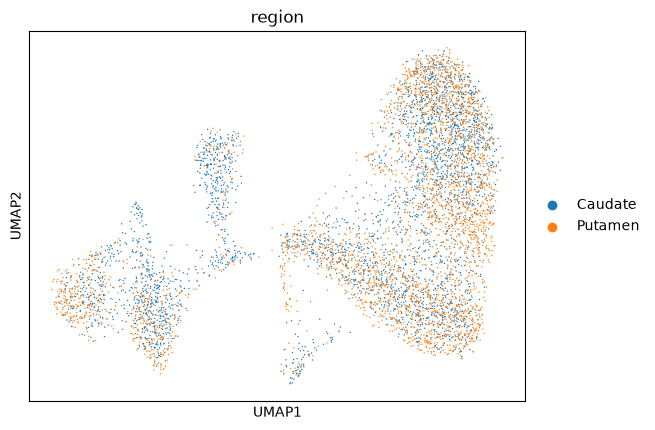

In [19]:
sc.pl.umap(
    smdata,
    color="region",
    size=4,
    save='_region_sr.png'
)

In [20]:
smdata.var.head()

,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection
MIR1302-2HG,False,False,7,0.001085,99.891473,7.0,7,False,0.001198,0.111550,-0.204768,0,False
AL627309.1,False,False,343,0.058605,94.682171,378.0,343,False,0.171446,1.015958,0.081568,3,False
AL627309.2,False,False,6,0.000930,99.906977,6.0,6,False,0.001179,0.103501,-0.193936,0,False
AL627309.5,False,False,1044,0.223101,83.813953,1439.0,1044,False,0.349952,0.792574,-0.574482,2,False
AL627309.4,False,False,6,0.000930,99.906977,6.0,6,False,0.001010,0.093398,-0.117857,0,False


In [21]:
#Calculate the LISI values for harmony integrated data
mtadata = mdata.obs[[batch_key]].copy()
harmony_lisi = (hm.compute_lisi(X=hmdata.obsm['X_pca_harmony'],
                                metadata=mtadata,
                                label_colnames=[batch_key]))
df_lisi = pd.DataFrame()
df_lisi['harmony'] = pd.DataFrame(harmony_lisi)

In [22]:
#Calculate the LISI values for scanorama integrated data
mtadata = mdata.obs[[batch_key]].copy()
scanorama_lisi = (hm.compute_lisi(X=smdata.obsm['X_scanorama'],
                                metadata=mtadata,
                                label_colnames=[batch_key]))
df_lisi['scanorama'] = pd.DataFrame(scanorama_lisi)

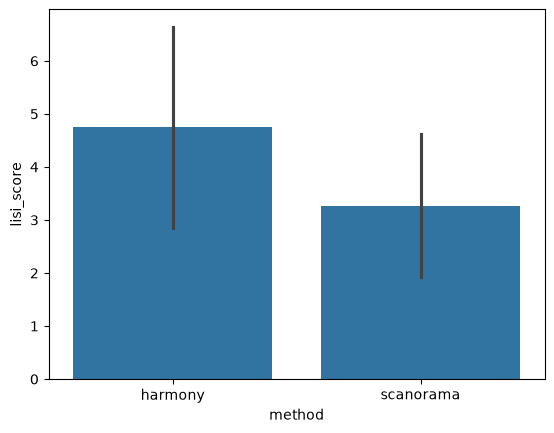

In [23]:
#Create a bar plot of lisi scores across methods
df_lisi = df_lisi.melt(var_name="method", value_name="lisi_score")
sns.barplot(data=df_lisi, x='method', y='lisi_score', errorbar='sd')
plt.savefig(script_loc.parent / 'outputs/integration_figures/lisi_scores.png', dpi=300)
plt.show()

In [24]:
hmdata.write_h5ad(script_loc.parent / 'data/intermediate/hm_adjust.h5ad')
smdata.write_h5ad(script_loc.parent / 'data/intermediate/sr_adjust.h5ad')
mdata.write_h5ad(script_loc.parent / 'data/intermediate/non_adjust.h5ad')